# Phase 2 · Notebook 1: Data preprocessing and stationarity
**Dataset:** `data_2000_2019.csv`: monthly dengue cases for 558 IBGE micro-regions in Brazil, 2000–2019.
**Scope:** Rio de Janeiro state (`state_code` 33, 18 micro-regions), aggregated into one monthly series.
**Outputs:** `data/processed/rj_monthly_dengue.csv`, `outputs/figures/*.png`, `outputs/stationarity_tests.csv`.

**Data note:** the file is monthly (column `month`), not annual. The "districts" in the file are IBGE micro-regions.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore", message=".*look-up table.*")  # KPSS p-value bounds

In [2]:
# Paths work whether the notebook is run from notebooks/ or from the project root
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "data_2000_2019.csv"
PROC_PATH = ROOT / "data" / "processed" / "rj_monthly_dengue.csv"
FIG_DIR = ROOT / "outputs" / "figures"
OUT_DIR = ROOT / "outputs"
for p in (PROC_PATH.parent, FIG_DIR):
    p.mkdir(parents=True, exist_ok=True)

STATE_CODE = 33          # Rio de Janeiro
START_YEAR = 2001        # 2000 has no dengue counts in the file (checked below)
SEASONAL_PERIOD = 12     # monthly data
plt.rcParams["figure.figsize"] = (11, 4)

## 1. Load and check the raw file

In [3]:
raw = pd.read_csv(RAW_PATH)
print("Shape:", raw.shape)
print("Years:", raw.year.min(), "-", raw.year.max())
print("Micro-regions:", raw.micro_code.nunique(), "| states:", raw.state_name.nunique())
raw.head(3)

Shape: (133920, 26)
Years: 2000 - 2019
Micro-regions: 558 | states: 27


,micro_code,micro_name,micro_name_ibge,meso_code,meso_name,state_code,state_name,region_code,region_name,biome_code,...,time,dengue_cases,population,pop_density,tmax,tmin,pdsi,urban,water_network,water_shortage
0,11001,Porto Velho,PORTO VELHO,1101,Madeira-Guaporé,11,Rondônia,1,North,5,...,1,NaN,NaN,NaN,30.544556,21.751202,-1.790602,85.20,33.57,0.2245
1,11002,Guajar<e1>-Mirim,GUAJARÁ-MIRIM,1101,Madeira-Guaporé,11,Rondônia,1,North,5,...,1,NaN,NaN,NaN,31.005884,21.641306,0.629408,72.31,27.43,0.0873
2,11003,Ariquemes,ARIQUEMES,1102,Leste Rondoniense,11,Rondônia,1,North,5,...,1,NaN,NaN,NaN,30.444357,21.492065,-3.455422,66.91,27.76,0.1871


In [4]:
missing = raw[raw.dengue_cases.isna()]
print("Rows with missing dengue_cases:", len(missing))
print(missing.groupby("year").size())

Rows with missing dengue_cases: 6696
year
2000    6696
dtype: int64


Every micro-region is missing dengue counts for all of 2000, so the usable range starts in January 2001.

## 2. Build the Rio de Janeiro monthly series
Summing the 18 micro-regions gives one state-level count per month. Population is summed the same way.

In [5]:
rj = raw[(raw.state_code == STATE_CODE) & (raw.year >= START_YEAR)]
monthly = (rj.groupby(["year", "month"], as_index=False)
             .agg(cases=("dengue_cases", "sum"), population=("population", "sum")))
monthly["date"] = pd.to_datetime(dict(year=monthly.year, month=monthly.month, day=1))
series = monthly.set_index("date")[["cases", "population"]].sort_index().asfreq("MS")

print("Months:", len(series), "| range:", series.index.min().date(), "to", series.index.max().date())
print("Missing values:", series.isna().sum().to_dict())
assert series.isna().sum().sum() == 0, "Gaps found: inspect before modelling"
assert series.index.is_monotonic_increasing
series.head()

Months: 228 | range: 2001-01-01 to 2019-12-01
Missing values: {'cases': 0, 'population': 0}


,cases,population
date,,
2001-01-01,3147.0,14558545.0
2001-02-01,6069.0,14558545.0
2001-03-01,9228.0,14558545.0
2001-04-01,16235.0,14558545.0
2001-05-01,13855.0,14558545.0


In [6]:
series.reset_index().to_csv(PROC_PATH, index=False)
print("Saved:", PROC_PATH.relative_to(ROOT))

Saved: data/processed/rj_monthly_dengue.csv


In [7]:
series["log_cases"] = np.log1p(series["cases"])  # log(cases + 1) stabilises the large epidemic swings

## 3. Visual inspection
**What the raw series shows:** large epidemic years (2002 at about 250,000 cases, then 2008, 2011–2013 and 2015–2016) alternate with quiet years (2003–2005, 2009, 2014, 2017–2018). Within each year, cases peak in March and April and bottom out in August and September. The seasonal profile below shows the same pattern in log scale.

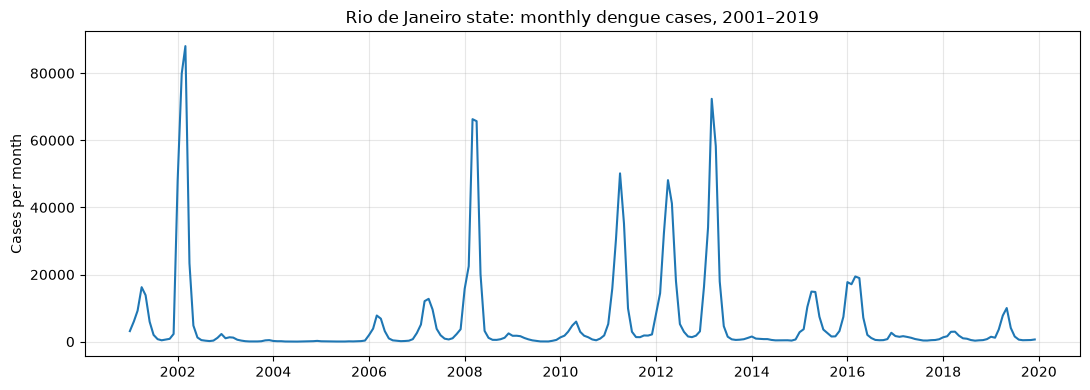

In [ ]:
fig, ax = plt.subplots()
ax.plot(series.index, series["cases"], color="tab:blue", lw=1.5)
ax.set_title("Rio de Janeiro state: monthly dengue cases, 2001–2019")
ax.set_ylabel("Cases per month")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_raw_series.png", dpi=150)
plt.show()

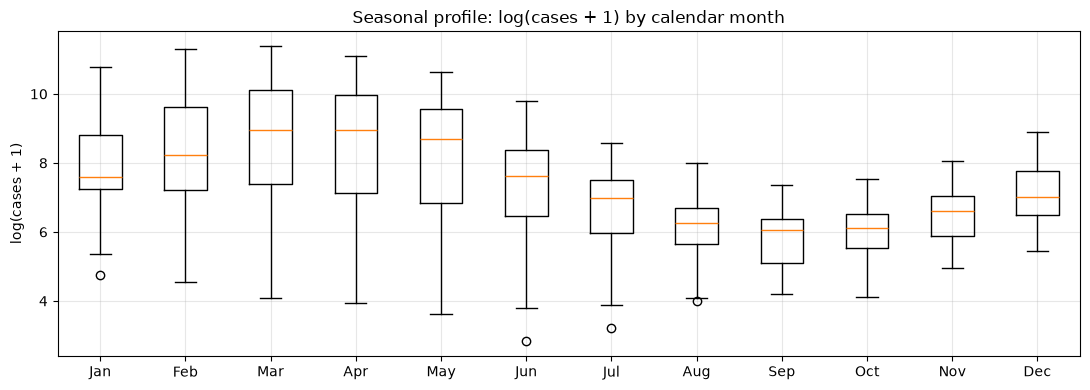

In [9]:
fig, ax = plt.subplots()
groups = [series.loc[series.index.month == m, "log_cases"] for m in range(1, 13)]
ax.boxplot(groups, tick_labels=["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Seasonal profile: log(cases + 1) by calendar month")
ax.set_ylabel("log(cases + 1)")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_monthly_boxplot.png", dpi=150)
plt.show()

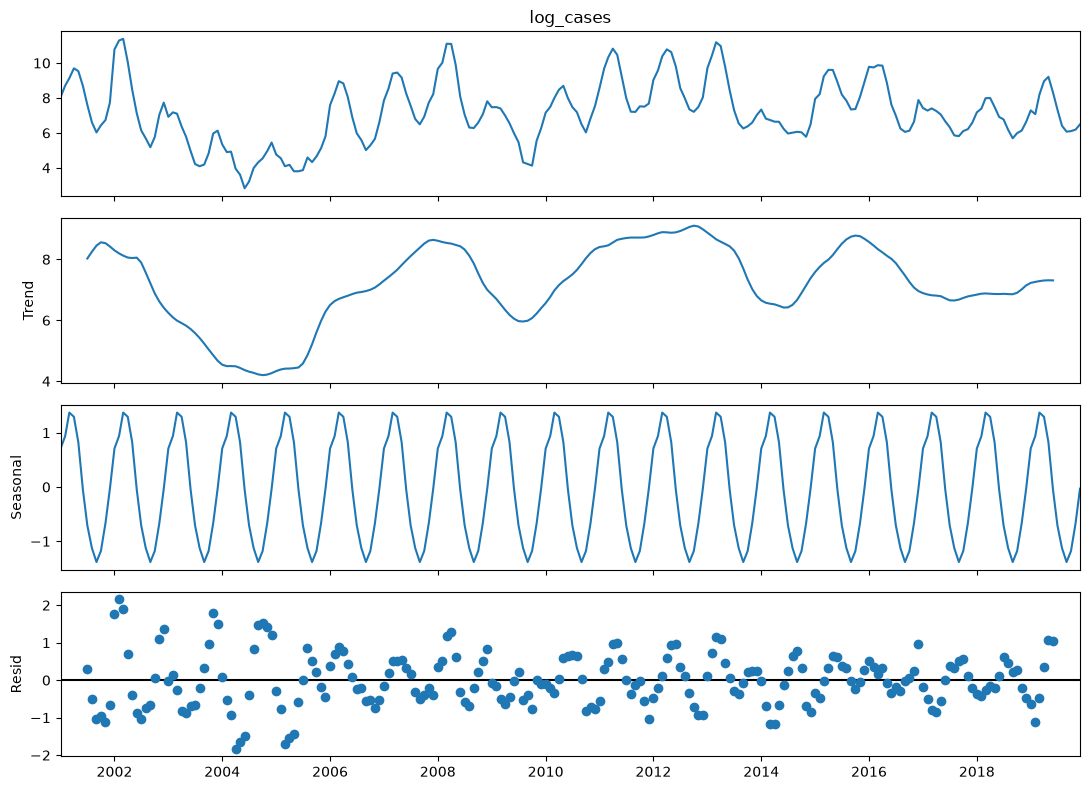

Strength of seasonality: 0.65  (0 = none, 1 = purely seasonal)


In [10]:
decomp = seasonal_decompose(series["log_cases"], model="additive", period=SEASONAL_PERIOD)
fig = decomp.plot()
fig.set_size_inches(11, 8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_decomposition_log.png", dpi=150)
plt.show()

# Strength of seasonality (Hyndman): 1 - Var(residual) / Var(seasonal + residual), bounded to [0, 1]
seas_plus_resid = (decomp.seasonal + decomp.resid).dropna()
strength = max(0.0, 1 - decomp.resid.dropna().var() / seas_plus_resid.var())
print(f"Strength of seasonality: {strength:.2f}  (0 = none, 1 = purely seasonal)")

## 4. Stationarity checks
- **ADF** (Augmented Dickey–Fuller): null = unit root (non-stationary). A small p-value means stationary.
- **KPSS**: null = stationary. A large p-value means stationary. The statistic's p-value is bounded to [0.01, 0.10] by its lookup table.

Each candidate transformation is tested so the differencing choice is justified by evidence rather than guessed.

In [11]:
def stationarity_report(x, label):
    x = x.dropna()
    adf_stat, adf_p, *_ = adfuller(x, autolag="AIC")
    kpss_stat, kpss_p, *_ = kpss(x, regression="c", nlags="auto")
    return {"series": label, "ADF_stat": adf_stat, "ADF_p": adf_p,
            "KPSS_stat": kpss_stat, "KPSS_p": kpss_p}

candidates = {
    "raw cases": series["cases"],
    "log(cases+1)": series["log_cases"],
    "log, seasonal diff (D=1)": series["log_cases"].diff(SEASONAL_PERIOD),
    "log, seasonal + regular diff (D=1, d=1)": series["log_cases"].diff(SEASONAL_PERIOD).diff(),
}
stationarity = pd.DataFrame([stationarity_report(v, k) for k, v in candidates.items()]).set_index("series")
stationarity.round(4).to_csv(OUT_DIR / "stationarity_tests.csv")
stationarity.round(4)

/var/folders/0h/v2ksz4wn24b34zzbtv41dsb00000gn/T/ipykernel_17880/3274901837.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_stat, adf_p, *_ = adfuller(x, autolag="AIC")
/var/folders/0h/v2ksz4wn24b34zzbtv41dsb00000gn/T/ipykernel_17880/3274901837.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_stat, kpss_p, *_ = kpss(x

,ADF_stat,ADF_p,KPSS_stat,KPSS_p
series,,,,
raw cases,-6.3322,0.0000,0.1098,0.1
log(cases+1),-3.1236,0.0249,0.3141,0.1
"log, seasonal diff (D=1)",-4.2889,0.0005,0.0725,0.1
"log, seasonal + regular diff (D=1, d=1)",-5.0193,0.0000,0.0382,0.1


**Reading the results**
- **Raw cases and log(cases+1):** ADF rejects a unit root and KPSS does not reject stationarity, so the level has no clear random-walk trend. The main structure is the repeating annual cycle (seasonal strength 0.65) and the large epidemic swings.
- **Log level** is the less settled of the two: its KPSS statistic (0.31) sits close to the 10% critical value (0.35). The log transform is still kept because it reduces the influence of the 2002, 2008 and 2013 epidemic peaks.
- **Seasonal differencing (D = 1)** gives the clearest stationary series: ADF p = 0.0005 and KPSS statistic 0.07, well inside the 10% critical value. This supports D = 1 for the seasonal models.
- **Regular differencing (d = 1) on top** also passes (ADF p < 0.001, KPSS 0.04). Stationarity alone cannot choose between d = 0 and d = 1, because both pass. That choice is made in Notebook 2 using residual whiteness (Ljung-Box) and AIC within each differencing order. In Notebook 2, with D = 1 and d = 0, no candidate passes the residual test at the annual lag.

## 5. ACF and PACF for model-order selection
Plotted for two series: after seasonal differencing only (D = 1), and after seasonal plus regular differencing (D = 1, d = 1).

**What the plots show:** after seasonal differencing alone, the ACF decays slowly and the PACF cuts off after lag 1 with a negative spike at lag 2. The PACF also has spikes at lags 13 and 14, which suggests a seasonal AR term. Lag-1 PACF is about 0.9, so the series is highly persistent: multi-month epidemic runs. Persistence like this often points to regular differencing as well, which is why the second plot is included.

**Order grid carried forward:** p and q in {0, 1, 2}, P and Q in {0, 1}, with d in {0, 1} and D = 1 for SARIMA. Notebook 2 selects among these.

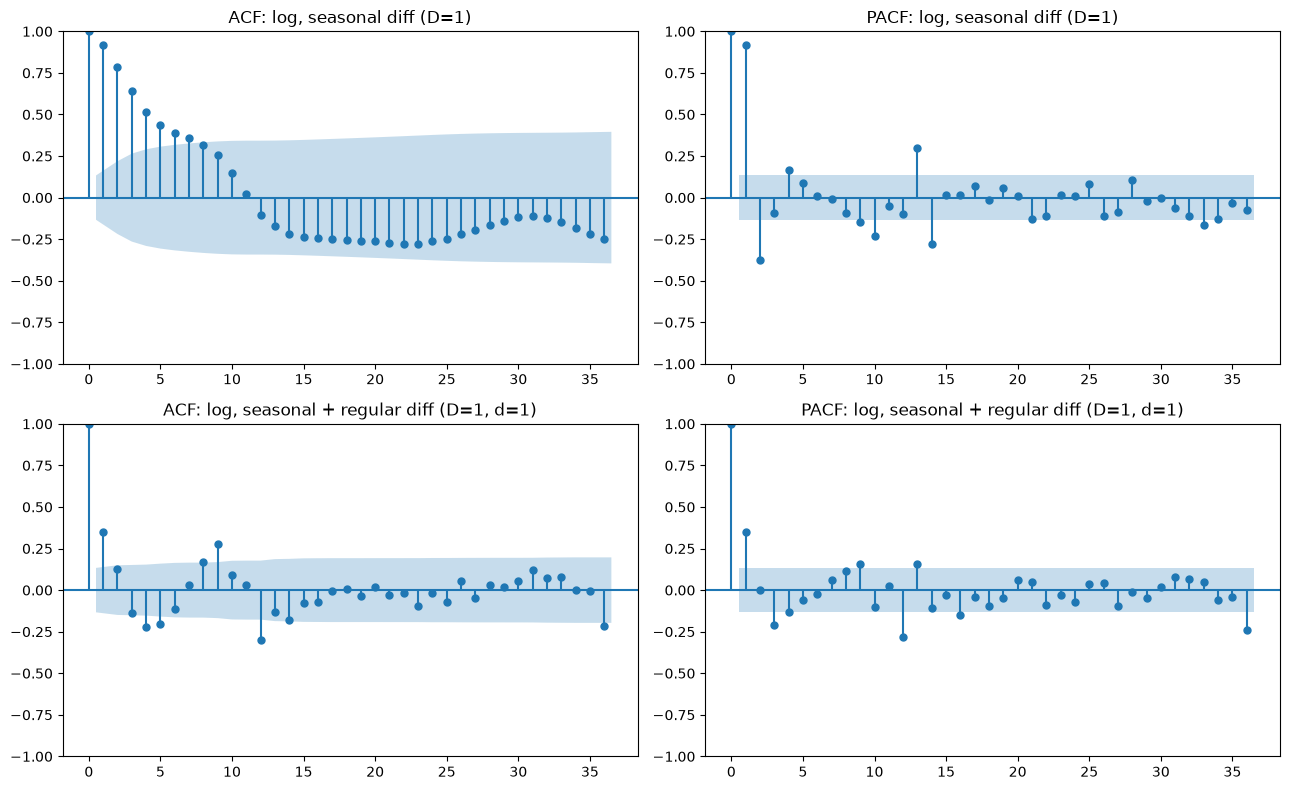

In [12]:
x_s = series["log_cases"].diff(SEASONAL_PERIOD).dropna()             # D = 1
x_sd = series["log_cases"].diff(SEASONAL_PERIOD).diff().dropna()    # D = 1, d = 1

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
plot_acf(x_s, lags=36, ax=axes[0, 0]);  axes[0, 0].set_title("ACF: log, seasonal diff (D=1)")
plot_pacf(x_s, lags=36, ax=axes[0, 1], method="ywm"); axes[0, 1].set_title("PACF: log, seasonal diff (D=1)")
plot_acf(x_sd, lags=36, ax=axes[1, 0]); axes[1, 0].set_title("ACF: log, seasonal + regular diff (D=1, d=1)")
plot_pacf(x_sd, lags=36, ax=axes[1, 1], method="ywm"); axes[1, 1].set_title("PACF: log, seasonal + regular diff (D=1, d=1)")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_acf_pacf.png", dpi=150)
plt.show()

## 6. Decisions carried into Notebook 2
| Decision | Choice | Reason |
|---|---|---|
| Study area | Rio de Janeiro state, 18 micro-regions summed | One series with enough history; state-level totals are less noisy than single micro-regions |
| Period | Jan 2001 to Dec 2019 (228 months) | 2000 has no dengue counts in the file |
| Transform | log(cases + 1) for ARIMA, SARIMA and Holt-Winters additive | Stabilises the epidemic swings; `+1` handles zero counts |
| Regular differencing | d = 1 (chosen in Notebook 2) | Both d = 0 and d = 1 pass the stationarity tests; with D = 1, only d = 1 gives white SARIMA residuals |
| Seasonal differencing | D = 1, period 12 | Seasonal strength 0.65; seasonal difference gives the clearest stationary series |
| Model-order rule | Lowest AIC among models whose residuals pass Ljung-Box, within one differencing order | AIC is only comparable within the same differencing; residual whiteness decides the rest |
| Train / test | Jan 2001 to Dec 2017 (204 months) / Jan 2018 to Dec 2019 (24 months) | Time-ordered hold-out; the last two years are the test window |